<a href="https://colab.research.google.com/github/sultanki/CDISC-Project/blob/main/SDTM_hands_on.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SDTM, hands-on: from the CRF pages you know to the datasets

Real sample data from the CDISC pilot study (CDISCPILOT01, a public Alzheimer's study with 306 subjects).
You already know these data as CRF pages. SDTM is just the agreed way to lay them out in rows and columns.

**How to use this notebook**
1. Run the cells top to bottom (Shift+Enter).
2. Each **Try it** box has a question. Write your own query first, then run the **Solution** cell below it.
3. Everything is SQL (SQLite) so you can use what you already know. Python is only used to run the queries.

**Parts**
1. The setup
2. One AE row, read back to the CRF
3. DM: one row per subject
4. AE: your safety data
5. SAE and AE reconciliation check (a real finding in this data)
6. Findings domains: vitals and labs
7. Exposure and concomitant meds
8. Mapping and lineage: CRF to SDTM, the way you would spec it
9. How to talk about this in an interview

## Part 1. The setup

In [5]:
import sqlite3, pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)

con = sqlite3.connect(":memory:")
for d in ["dm", "ae", "cm", "ex", "vs", "lb", "mh", "sv", "ds"]:
    df = pd.read_csv(f"{d}.csv")
    for c in df.columns:
        if c.endswith("SEQ"):
            df[c] = df[c].astype("Int64")
    df.to_sql(d, con, index=False)

def q(sql):
    """Run a SQL query and show the result as a table."""
    return pd.read_sql(sql, con)

q("SELECT 'dm' AS dataset, COUNT(*) AS rows FROM dm UNION ALL SELECT 'ae', COUNT(*) FROM ae UNION ALL SELECT 'cm', COUNT(*) FROM cm UNION ALL SELECT 'ex', COUNT(*) FROM ex UNION ALL SELECT 'vs', COUNT(*) FROM vs UNION ALL SELECT 'lb (7 tests only)', COUNT(*) FROM lb")

,dataset,rows
0,dm,306
1,ae,1191
2,cm,7510
3,ex,591
4,vs,29643
5,lb (7 tests only),12697


In [6]:
q("""
SELECT 'dm' AS dataset, COUNT(*) AS rows FROM dm
UNION ALL SELECT 'ae', COUNT(*) FROM ae
UNION ALL SELECT 'cm', COUNT(*) FROM cm
UNION ALL SELECT 'ex', COUNT(*) FROM ex
UNION ALL SELECT 'vs', COUNT(*) FROM vs
UNION ALL SELECT 'lb', COUNT(*) FROM lb
UNION ALL SELECT 'mh', COUNT(*) FROM mh
UNION ALL SELECT 'sv', COUNT(*) FROM sv
UNION ALL SELECT 'ds', COUNT(*) FROM ds
""")

,dataset,rows
0,dm,306
1,ae,1191
2,cm,7510
3,ex,591
4,vs,29643
5,lb,12697
6,mh,1818
7,sv,3559
8,ds,596


In [7]:
q("""
SELECT d.USUBJID, d.SITEID, d.AGE, d.SEX, d.ARM, s.DSDECOD
FROM dm d
JOIN ds s ON d.USUBJID = s.USUBJID
WHERE s.DSDECOD = 'COMPLETED'
LIMIT 5
""")

,USUBJID,SITEID,AGE,SEX,ARM,DSDECOD
0,01-701-1015,701,63.0,F,Placebo,COMPLETED
1,01-701-1028,701,71.0,M,Xanomeline High Dose,COMPLETED
2,01-701-1034,701,77.0,F,Xanomeline High Dose,COMPLETED
3,01-701-1097,701,68.0,M,Xanomeline Low Dose,COMPLETED
4,01-701-1118,701,52.0,M,Placebo,COMPLETED


In [8]:
q("SELECT * FROM ds LIMIT 5")

,STUDYID,DOMAIN,USUBJID,DSSEQ,DSSPID,DSTERM,DSDECOD,DSCAT,VISITNUM,VISIT,DSDTC,DSSTDTC,DSSTDY
0,CDISCPILOT01,DS,01-701-1015,1,NaN,PROTOCOL COMPLETED,COMPLETED,DISPOSITION EVENT,13.0,WEEK 26,2014-07-02,2014-07-02,182.0
1,CDISCPILOT01,DS,01-701-1015,2,NaN,FINAL LAB VISIT,FINAL LAB VISIT,OTHER EVENT,13.0,WEEK 26,2014-07-02T11:45,2014-07-02,182.0
2,CDISCPILOT01,DS,01-701-1023,1,24.0,ADVERSE EVENT,ADVERSE EVENT,DISPOSITION EVENT,5.0,WEEK 4,2012-09-02,2012-09-02,29.0
3,CDISCPILOT01,DS,01-701-1023,2,NaN,FINAL LAB VISIT,FINAL LAB VISIT,OTHER EVENT,5.0,WEEK 4,2012-09-02T10:15,2012-09-02,29.0
4,CDISCPILOT01,DS,01-701-1023,3,NaN,FINAL RETRIEVAL VISIT,FINAL RETRIEVAL VISIT,OTHER EVENT,201.0,RETRIEVAL,2013-02-18,2013-02-18,198.0


In [9]:
q("SELECT * FROM sv LIMIT 5")

,STUDYID,DOMAIN,USUBJID,VISITNUM,VISIT,VISITDY,SVSTDTC,SVENDTC
0,CDISCPILOT01,SV,01-701-1015,1.0,SCREENING 1,-7.0,2013-12-26,2013-12-26
1,CDISCPILOT01,SV,01-701-1015,2.0,SCREENING 2,-1.0,2013-12-31,2013-12-31
2,CDISCPILOT01,SV,01-701-1015,3.0,BASELINE,1.0,2014-01-02,2014-01-02
3,CDISCPILOT01,SV,01-701-1015,3.5,AMBUL ECG PLACEMENT,13.0,2014-01-14,2014-01-14
4,CDISCPILOT01,SV,01-701-1015,4.0,WEEK 2,14.0,2014-01-16,2014-01-16


In [10]:
q("SELECT * FROM mh LIMIT 5")

,STUDYID,DOMAIN,USUBJID,MHSEQ,MHSPID,MHTERM,MHLLT,MHDECOD,MHHLT,MHHLGT,MHCAT,MHBODSYS,MHSEV,VISITNUM,VISIT,VISITDY,MHDTC,MHSTDTC,MHDY
0,CDISCPILOT01,MH,01-701-1015,9,None,ALZHEIMER'S DISEASE,None,None,None,None,PRIMARY DIAGNOSIS,None,None,1.0,SCREENING 1,-7.0,2013-12-26,2010-04-30,-7.0
1,CDISCPILOT01,MH,01-701-1015,1,E01,VERBATIM_0135,PALPITATIONS,PALPITATIONS,HLT_0493,HLGT_0593,SIGNIFICANT PRE-EXISTING CONDITION,CARDIAC DISORDERS,MILD,1.0,SCREENING 1,-7.0,2013-12-26,None,-7.0
2,CDISCPILOT01,MH,01-701-1015,8,None,VERBATIM_0140,SUBTOTAL HYSTERECTOMY,HYSTERECTOMY,HLT_0675,HLGT_0657,HISTORICAL DIAGNOSIS,SURGICAL AND MEDICAL PROCEDURES,None,1.0,SCREENING 1,-7.0,2013-12-26,1986,-7.0
3,CDISCPILOT01,MH,01-701-1015,2,E03,VERBATIM_0301,HEADACHE,HEADACHE,HLT_0064,HLGT_0344,SIGNIFICANT PRE-EXISTING CONDITION,NERVOUS SYSTEM DISORDERS,MILD,1.0,SCREENING 1,-7.0,2013-12-26,None,-7.0
4,CDISCPILOT01,MH,01-701-1015,10,None,VERBATIM_0539,GALLBLADDER STONES,CHOLELITHIASIS,HLT_0084,HLGT_0177,HISTORICAL DIAGNOSIS,HEPATOBILIARY DISORDERS,None,1.0,SCREENING 1,-7.0,2013-12-26,2012,-7.0


In [11]:
q("SELECT * FROM dm LIMIT 5")

,STUDYID,DOMAIN,USUBJID,SUBJID,RFSTDTC,RFENDTC,RFXSTDTC,RFXENDTC,RFICDTC,RFPENDTC,DTHDTC,DTHFL,SITEID,AGE,AGEU,SEX,RACE,ETHNIC,ARMCD,ARM,ACTARMCD,ACTARM,COUNTRY,DMDTC,DMDY
0,CDISCPILOT01,DM,01-701-1015,1015,2014-01-02,2014-07-02,2014-01-02,2014-07-02,None,2014-07-02T11:45,None,None,701,63.0,YEARS,F,WHITE,HISPANIC OR LATINO,Pbo,Placebo,Pbo,Placebo,USA,2013-12-26,-7.0
1,CDISCPILOT01,DM,01-701-1023,1023,2012-08-05,2012-09-02,2012-08-05,2012-09-01,None,2013-02-18,None,None,701,64.0,YEARS,M,WHITE,HISPANIC OR LATINO,Pbo,Placebo,Pbo,Placebo,USA,2012-07-22,-14.0
2,CDISCPILOT01,DM,01-701-1028,1028,2013-07-19,2014-01-14,2013-07-19,2014-01-14,None,2014-01-14T11:10,None,None,701,71.0,YEARS,M,WHITE,NOT HISPANIC OR LATINO,Xan_Hi,Xanomeline High Dose,Xan_Hi,Xanomeline High Dose,USA,2013-07-11,-8.0
3,CDISCPILOT01,DM,01-701-1033,1033,2014-03-18,2014-04-14,2014-03-18,2014-03-31,None,2014-09-15,None,None,701,74.0,YEARS,M,WHITE,NOT HISPANIC OR LATINO,Xan_Lo,Xanomeline Low Dose,Xan_Lo,Xanomeline Low Dose,USA,2014-03-10,-8.0
4,CDISCPILOT01,DM,01-701-1034,1034,2014-07-01,2014-12-30,2014-07-01,2014-12-30,None,2014-12-30T09:50,None,None,701,77.0,YEARS,F,WHITE,NOT HISPANIC OR LATINO,Xan_Hi,Xanomeline High Dose,Xan_Hi,Xanomeline High Dose,USA,2014-06-24,-7.0


In [12]:
q("""
SELECT
    ARM,
    COUNT(*) AS total_subjects,
    ROUND(AVG(AGE), 1) AS mean_age,
    MIN(AGE) AS min_age,
    MAX(AGE) AS max_age,
    SUM(CASE WHEN SEX = 'F' THEN 1 ELSE 0 END) AS female_count,
    SUM(CASE WHEN SEX = 'M' THEN 1 ELSE 0 END) AS male_count
FROM dm
GROUP BY ARM
ORDER BY total_subjects DESC
""")

,ARM,total_subjects,mean_age,min_age,max_age,female_count,male_count
0,Placebo,86,75.2,52.0,89.0,53,33
1,Xanomeline Low Dose,84,75.7,51.0,88.0,50,34
2,Xanomeline High Dose,84,74.4,56.0,88.0,40,44
3,Screen Failure,52,75.1,50.0,89.0,36,16


In [13]:
q("""
SELECT
    d.ARM,
    COUNT(a.USUBJID) AS total_adverse_events
FROM dm d
LEFT JOIN ae a ON d.USUBJID = a.USUBJID
GROUP BY d.ARM
ORDER BY total_adverse_events DESC
""")

,ARM,total_adverse_events
0,Xanomeline High Dose,455
1,Xanomeline Low Dose,435
2,Placebo,301
3,Screen Failure,0


In [14]:
q("""
SELECT STUDYID, DOMAIN, USUBJID, LBSEQ, LBTESTCD, LBTEST, LBCAT, LBORRES, LBORRESU, LBNRIND, VISIT, LBDTC
FROM lb
WHERE USUBJID = '01-701-1015'
ORDER BY LBSEQ
LIMIT 5
""")

,STUDYID,DOMAIN,USUBJID,LBSEQ,LBTESTCD,LBTEST,LBCAT,LBORRES,LBORRESU,LBNRIND,VISIT,LBDTC
0,CDISCPILOT01,LB,01-701-1015,3,ALT,Alanine Aminotransferase,CHEMISTRY,27,U/L,NORMAL,SCREENING 1,2013-12-26T14:45
1,CDISCPILOT01,LB,01-701-1015,5,AST,Aspartate Aminotransferase,CHEMISTRY,40,U/L,HIGH,SCREENING 1,2013-12-26T14:45
2,CDISCPILOT01,LB,01-701-1015,7,BILI,Bilirubin,CHEMISTRY,0.6,mg/dL,NORMAL,SCREENING 1,2013-12-26T14:45
3,CDISCPILOT01,LB,01-701-1015,14,CREAT,Creatinine,CHEMISTRY,0.9,mg/dL,NORMAL,SCREENING 1,2013-12-26T14:45
4,CDISCPILOT01,LB,01-701-1015,17,GLUC,Glucose,CHEMISTRY,85,mg/dL,NORMAL,SCREENING 1,2013-12-26T14:45


In [15]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


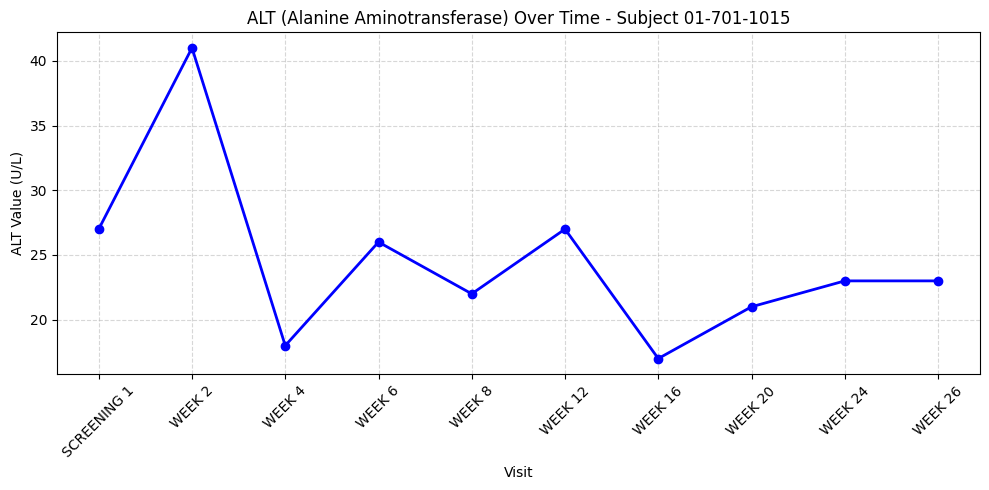

In [16]:
import matplotlib.pyplot as plt

# Query the ALT lab results for subject 01-701-1015
alt_data = q("""
SELECT VISIT, LBDTC, CAST(LBORRES AS REAL) AS alt_val
FROM lb
WHERE USUBJID = '01-701-1015' AND LBTESTCD = 'ALT'
ORDER BY LBDTC
""")

# Plot ALT values over time
plt.figure(figsize=(10, 5))
plt.plot(alt_data['VISIT'], alt_data['alt_val'], marker='o', linestyle='-', color='b', linewidth=2)
plt.title('ALT (Alanine Aminotransferase) Over Time - Subject 01-701-1015')
plt.xlabel('Visit')
plt.ylabel('ALT Value (U/L)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,VISIT,LBDTC,alt_val
0,SCREENING 1,2013-12-26T14:45,27.0
1,WEEK 2,2014-01-16T13:17,41.0
2,WEEK 4,2014-01-30T08:50,18.0
3,WEEK 6,2014-02-12T12:56,26.0
4,WEEK 8,2014-03-05T12:25,22.0
5,WEEK 12,2014-03-26T15:15,27.0
6,WEEK 16,2014-05-07T11:21,17.0
7,WEEK 20,2014-05-21T10:58,21.0
8,WEEK 24,2014-06-18T13:00,23.0
9,WEEK 26,2014-07-02T11:45,23.0


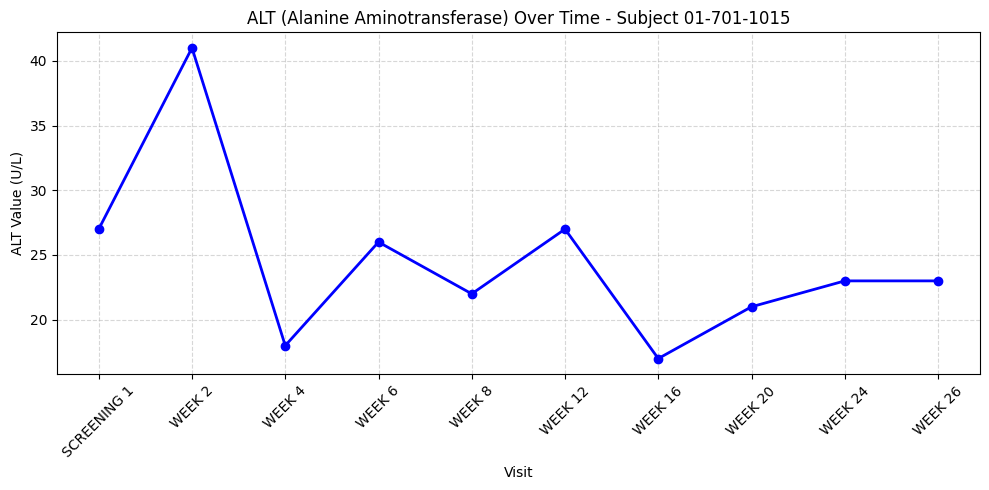

In [17]:
# Fetch the data
alt_data = q("""
SELECT VISIT, LBDTC, CAST(LBORRES AS REAL) AS alt_val
FROM lb
WHERE USUBJID = '01-701-1015' AND LBTESTCD = 'ALT'
ORDER BY LBDTC
""")

# Force the notebook to render the data table first
display(alt_data)

# Now plot the chart
plt.figure(figsize=(10, 5))
plt.plot(alt_data['VISIT'], alt_data['alt_val'], marker='o', linestyle='-', color='b', linewidth=2)
plt.title('ALT (Alanine Aminotransferase) Over Time - Subject 01-701-1015')
plt.xlabel('Visit')
plt.ylabel('ALT Value (U/L)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
import os
import shutil

# Define target folder in Google Drive
target_dir = '/content/drive/MyDrive/CDISC_Data'
os.makedirs(target_dir, exist_ok=True)

# List of CSV files used in this notebook
csv_files = ['dm.csv', 'ae.csv', 'cm.csv', 'ex.csv', 'vs.csv', 'lb.csv', 'ds.csv', 'mh.csv', 'sv.csv']

for file in csv_files:
    if os.path.exists(file):
        shutil.copy(file, os.path.join(target_dir, file))
        print(f"Successfully copied {file} to {target_dir}")
    else:
        print(f"Warning: {file} not found in local workspace.")

Successfully copied dm.csv to /content/drive/MyDrive/CDISC_Data
Successfully copied ae.csv to /content/drive/MyDrive/CDISC_Data
Successfully copied cm.csv to /content/drive/MyDrive/CDISC_Data
Successfully copied ex.csv to /content/drive/MyDrive/CDISC_Data
Successfully copied vs.csv to /content/drive/MyDrive/CDISC_Data
Successfully copied lb.csv to /content/drive/MyDrive/CDISC_Data
Successfully copied ds.csv to /content/drive/MyDrive/CDISC_Data
Successfully copied mh.csv to /content/drive/MyDrive/CDISC_Data
Successfully copied sv.csv to /content/drive/MyDrive/CDISC_Data


Six datasets (called **domains**): **DM** demographics, **AE** adverse events, **CM** concomitant meds, **EX** exposure, **VS** vital signs, **LB** labs.
Each one has a two-letter code, and every variable in it starts with that code (AETERM, VSTESTCD, LBSTRESN).
That is most of the naming rule.

The labs file here keeps only 7 tests (ALT, AST, BILI, CREAT, GLUC, SODIUM, HGB) so it stays small.

## Part 2. One AE row, read back to the CRF

Picture the AE CRF page for one subject. The site writes the event in their own words, picks severity and seriousness,
and enters dates. Here is a real row from the AE dataset for the first subject. Read each variable and ask:
*which CRF field was this?*

In [19]:
row = q("SELECT * FROM ae WHERE USUBJID = '01-701-1015' ORDER BY AESEQ LIMIT 1").T
row.columns = ["value"]
row

,value
STUDYID,CDISCPILOT01
DOMAIN,AE
USUBJID,01-701-1015
AESEQ,1
AESPID,E07
AETERM,APPLICATION SITE ERYTHEMA
AELLT,APPLICATION SITE REDNESS
AELLTCD,None
AEDECOD,APPLICATION SITE ERYTHEMA
AEPTCD,None


| SDTM variable | What it holds | CRF equivalent |
|---|---|---|
| STUDYID, DOMAIN | Study and which domain (AE) | Header |
| USUBJID | Unique subject ID across the whole study | Site number plus subject number, combined |
| AESEQ | Row number within the subject for this domain | Line number on the AE log |
| AESPID | Sponsor's own ID | The CRF line ID or page reference |
| AETERM | The verbatim text the site wrote | "Adverse event term" |
| AELLT, AEDECOD, AEHLT, AEHLGT, AEBODSYS | MedDRA levels: LLT, preferred term, HLT, HLGT, SOC | Coding done in data management |
| AESEV | MILD, MODERATE or SEVERE | Severity |
| AESER | Y or N, serious? | "Serious" checkbox |
| AESCAN, AESHOSP, AESLIFE, AESDTH, AESDISAB, AESCONG, AESOD | Seriousness criteria | The individual SAE criteria boxes |
| AEREL | Relationship to study drug | Causality |
| AEOUT | Outcome | Outcome |
| AESTDTC, AEENDTC | Start and end date, ISO 8601 text (YYYY-MM-DD) | Start date, end date |
| AESTDY, AEENDY | Study day relative to first dose | Derived, not collected |

Two ideas to hold on to:
- **One row per event**, with a sequence number. Tidy, not wide.
- **Dates are text in ISO format**, so partial dates (a year or a year-month) are allowed.

### Try it 2.1
Look at all the AEs for subject `01-701-1015`. How many are there, and which was the first by start date?

In [20]:
# Your turn: write your query here, for example q("SELECT ... FROM ae WHERE ...")

q("""
SELECT AESEQ, AETERM, AEDECOD, AESEV, AESER, AESTDTC, AEENDTC, AEOUT
FROM ae
WHERE USUBJID = '01-701-1015'
ORDER BY AESTDTC
""")

,AESEQ,AETERM,AEDECOD,AESEV,AESER,AESTDTC,AEENDTC,AEOUT
0,1,APPLICATION SITE ERYTHEMA,APPLICATION SITE ERYTHEMA,MILD,N,2014-01-03,None,NOT RECOVERED/NOT RESOLVED
1,2,APPLICATION SITE PRURITUS,APPLICATION SITE PRURITUS,MILD,N,2014-01-03,None,NOT RECOVERED/NOT RESOLVED
2,3,DIARRHOEA,DIARRHOEA,MILD,N,2014-01-09,2014-01-11,RECOVERED/RESOLVED


In [21]:
q("""
SELECT USUBJID, COUNT(*) AS total_aes
FROM ae
GROUP BY USUBJID
ORDER BY total_aes DESC
""")

,USUBJID,total_aes
0,01-701-1302,23
1,01-717-1004,19
2,01-718-1427,16
3,01-709-1029,16
4,01-704-1266,16
...,...,...
220,01-703-1175,1
221,01-701-1442,1
222,01-701-1203,1
223,01-701-1181,1


In [22]:
q("""
SELECT USUBJID, COUNT(*) AS total_aes
FROM ae
WHERE USUBJID = '01-701-1015'
""")

,USUBJID,total_aes
0,01-701-1015,3


**Solution**

In [23]:
q("""
SELECT AESEQ, AETERM, AEDECOD, AESEV, AESER, AESTDTC, AEENDTC, AEOUT
FROM ae
WHERE USUBJID = '01-701-1015'
ORDER BY AESTDTC
""")

,AESEQ,AETERM,AEDECOD,AESEV,AESER,AESTDTC,AEENDTC,AEOUT
0,1,APPLICATION SITE ERYTHEMA,APPLICATION SITE ERYTHEMA,MILD,N,2014-01-03,None,NOT RECOVERED/NOT RESOLVED
1,2,APPLICATION SITE PRURITUS,APPLICATION SITE PRURITUS,MILD,N,2014-01-03,None,NOT RECOVERED/NOT RESOLVED
2,3,DIARRHOEA,DIARRHOEA,MILD,N,2014-01-09,2014-01-11,RECOVERED/RESOLVED


## Part 3. DM: one row per subject

DM is the anchor. It has exactly one row per subject, and every other domain joins back to it through `USUBJID`.
It also holds the reference dates (`RFSTDTC`, `RFXSTDTC`, first dose) that study day is calculated from.

In [24]:
q("SELECT USUBJID, SITEID, AGE, SEX, RACE, ARM, RFXSTDTC, RFXENDTC FROM dm LIMIT 8")

,USUBJID,SITEID,AGE,SEX,RACE,ARM,RFXSTDTC,RFXENDTC
0,01-701-1015,701,63.0,F,WHITE,Placebo,2014-01-02,2014-07-02
1,01-701-1023,701,64.0,M,WHITE,Placebo,2012-08-05,2012-09-01
2,01-701-1028,701,71.0,M,WHITE,Xanomeline High Dose,2013-07-19,2014-01-14
3,01-701-1033,701,74.0,M,WHITE,Xanomeline Low Dose,2014-03-18,2014-03-31
4,01-701-1034,701,77.0,F,WHITE,Xanomeline High Dose,2014-07-01,2014-12-30
5,01-701-1047,701,85.0,F,WHITE,Placebo,2013-02-12,2013-03-09
6,01-701-1057,701,59.0,F,WHITE,Screen Failure,None,None
7,01-701-1097,701,68.0,M,WHITE,Xanomeline Low Dose,2014-01-01,2014-07-09


### Try it 3.1
How many subjects are in each treatment arm (`ARM`)? One arm is not a treatment group at all. Which one, and why is it there?

In [25]:
# Your turn: write your query here, for example q("SELECT ... FROM ae WHERE ...")

**Solution**

In [26]:
q("SELECT ARM, COUNT(*) AS subjects FROM dm GROUP BY ARM ORDER BY subjects DESC")

,ARM,subjects
0,Placebo,86
1,Xanomeline Low Dose,84
2,Xanomeline High Dose,84
3,Screen Failure,52


*Screen Failure* subjects were consented and screened but never dosed. They stay in DM (you do not erase people who consented),
and they have no `RFXSTDTC`. That one detail trips up many first analyses.

### Try it 3.2
Average age and the number of males and females in each of the three treatment arms (leave out screen failures).

In [27]:
# Your turn: write your query here, for example q("SELECT ... FROM ae WHERE ...")

**Solution**

In [28]:
q("""
SELECT ARM,
       COUNT(*) AS subjects,
       ROUND(AVG(AGE), 1) AS mean_age,
       SUM(CASE WHEN SEX = 'F' THEN 1 ELSE 0 END) AS female,
       SUM(CASE WHEN SEX = 'M' THEN 1 ELSE 0 END) AS male
FROM dm
WHERE ARM <> 'Screen Failure'
GROUP BY ARM
""")

,ARM,subjects,mean_age,female,male
0,Placebo,86,75.2,53,33
1,Xanomeline High Dose,84,74.4,40,44
2,Xanomeline Low Dose,84,75.7,50,34


## Part 4. AE: your safety data

### Try it 4.1
What are the 10 most common adverse events (by preferred term `AEDECOD`), and how many different subjects had each?
Count subjects, not rows, because one subject can have the same event twice.

In [29]:
# Your turn: write your query here, for example q("SELECT ... FROM ae WHERE ...")

**Solution**

In [30]:
q("""
SELECT AEDECOD, COUNT(*) AS events, COUNT(DISTINCT USUBJID) AS subjects
FROM ae
GROUP BY AEDECOD
ORDER BY subjects DESC
LIMIT 10
""")

,AEDECOD,events,subjects
0,PRURITUS,84,57
1,APPLICATION SITE PRURITUS,78,50
2,ERYTHEMA,59,38
3,APPLICATION SITE ERYTHEMA,46,30
4,RASH,45,29
5,DIZZINESS,34,22
6,APPLICATION SITE IRRITATION,41,21
7,APPLICATION SITE DERMATITIS,36,21
8,DIARRHOEA,21,18
9,SINUS BRADYCARDIA,24,17


### Try it 4.2
Join AE to DM. For each treatment arm, how many subjects had at least one AE, and what percent of the arm is that?
(This is the standard table every safety report starts with.)

In [31]:
# Your turn: write your query here, for example q("SELECT ... FROM ae WHERE ...")

**Solution**

In [32]:
q("""
SELECT d.ARM,
       COUNT(DISTINCT d.USUBJID) AS subjects,
       COUNT(DISTINCT a.USUBJID) AS with_ae,
       ROUND(100.0 * COUNT(DISTINCT a.USUBJID) / COUNT(DISTINCT d.USUBJID), 1) AS pct
FROM dm d
LEFT JOIN ae a ON a.USUBJID = d.USUBJID
WHERE d.ARM <> 'Screen Failure'
GROUP BY d.ARM
""")

,ARM,subjects,with_ae,pct
0,Placebo,86,69,80.2
1,Xanomeline High Dose,84,79,94.0
2,Xanomeline Low Dose,84,77,91.7


### Try it 4.3
Which body systems (`AEBODSYS`, the MedDRA SOC) have the most events, split by arm? Which arms stand out for skin-related events, and does it make clinical sense?

In [33]:
# Your turn: write your query here, for example q("SELECT ... FROM ae WHERE ...")

**Solution**

In [34]:
q("""
SELECT a.AEBODSYS,
       SUM(d.ARM = 'Placebo') AS placebo,
       SUM(d.ARM = 'Xanomeline Low Dose') AS low_dose,
       SUM(d.ARM = 'Xanomeline High Dose') AS high_dose
FROM ae a JOIN dm d ON d.USUBJID = a.USUBJID
GROUP BY a.AEBODSYS
ORDER BY placebo + low_dose + high_dose DESC
LIMIT 8
""")

,AEBODSYS,placebo,low_dose,high_dose
0,GENERAL DISORDERS AND ADMINISTRATION SITE CONDITIONS,48,120,124
1,SKIN AND SUBCUTANEOUS TISSUE DISORDERS,47,118,111
2,NERVOUS SYSTEM DISORDERS,16,40,45
3,CARDIAC DISORDERS,27,30,34
4,GASTROINTESTINAL DISORDERS,26,24,37
5,INFECTIONS AND INFESTATIONS,35,18,20
6,"RESPIRATORY, THORACIC AND MEDIASTINAL DISORDERS",15,16,22
7,PSYCHIATRIC DISORDERS,14,14,12


Skin and application-site events are far more common on the drug than on placebo, which makes sense because the drug is delivered by a skin patch (check `EXDOSFRM` in the EX domain and you will see PATCH).
Reading a table like this and asking "does that make clinical sense?" is the part no standard can do for you, and you have that instinct already.

## Part 5. SAE and AE reconciliation check (a real finding in this data)

In AE, `AESER` says whether an event is serious. The seven flags (`AESDTH`, `AESHOSP`, `AESLIFE`, `AESDISAB`, `AESCAN`, `AESCONG`, `AESOD`)
say *why*. If any flag is Y, `AESER` should be Y. That is a consistency check, the same kind of thing you do in SAE and AE reconciliation.

In [35]:
q("""
SELECT AESER,
       SUM(CASE WHEN AESDTH='Y' OR AESHOSP='Y' OR AESLIFE='Y' OR AESDISAB='Y' OR AESCAN='Y' OR AESCONG='Y' OR AESOD='Y' THEN 1 ELSE 0 END) AS rows_with_a_criterion,
       COUNT(*) AS rows
FROM ae
GROUP BY AESER
""")

,AESER,rows_with_a_criterion,rows
0,N,36,1188
1,Y,3,3


### Try it 5.1
List the AE rows where `AESER = 'N'` but at least one seriousness criterion is `Y`. Show subject, term, and which flags are set.
How would you raise this as a data query, and who would you send it to?

In [36]:
# Your turn: write your query here, for example q("SELECT ... FROM ae WHERE ...")

**Solution**

In [37]:
mismatch = q("""
SELECT USUBJID, AESEQ, AETERM, AESER, AESDTH, AESHOSP, AESLIFE, AESDISAB, AESCAN, AESCONG, AESOD
FROM ae
WHERE AESER = 'N'
  AND (AESDTH='Y' OR AESHOSP='Y' OR AESLIFE='Y' OR AESDISAB='Y' OR AESCAN='Y' OR AESCONG='Y' OR AESOD='Y')
""")
print(len(mismatch), "rows to query")
mismatch.head(10)

36 rows to query


,USUBJID,AESEQ,AETERM,AESER,AESDTH,AESHOSP,AESLIFE,AESDISAB,AESCAN,AESCONG,AESOD
0,01-701-1192,7,PNEUMONIA,N,N,Y,N,N,N,N,N
1,01-701-1192,10,PNEUMONIA,N,N,Y,N,N,N,N,N
2,01-701-1211,9,SUDDEN DEATH,N,Y,N,Y,N,N,N,N
3,01-704-1008,2,TRANSIENT ISCHAEMIC ATTACK,N,N,Y,N,N,N,N,N
4,01-704-1445,1,COMPLETED SUICIDE,N,Y,N,N,N,N,N,N
5,01-705-1393,3,COLON CANCER,N,N,Y,N,N,Y,N,N
6,01-706-1049,2,SYNCOPE,N,N,Y,N,N,N,N,N
7,01-708-1178,7,ATRIAL FIBRILLATION,N,N,Y,N,N,N,N,N
8,01-708-1178,6,DIZZINESS,N,N,Y,N,N,N,N,N
9,01-709-1259,5,BENIGN PROSTATIC HYPERPLASIA,N,N,Y,N,N,N,N,N


**How you would handle it.** Quote the subject, the AE term and sequence number, and the specific flag. Send it as a query to the site through the data manager,
asking whether the event is serious or the criterion was ticked in error. If it is serious, safety needs to know about it too.
The row identifiers (`USUBJID` plus `AESEQ`) are what let anyone find the exact CRF record again, which is lineage.

Note: this is a sample dataset, and I am not claiming it is an error in the original study. It is a good example of a check that finds something.

### Try it 5.2
How many AEs started on or after the subject's first dose (`RFXSTDTC` in DM)? These are the treatment-emergent ones.
Only compare when both dates are full dates (10 characters), because partial dates cannot be compared as text.

In [38]:
# Your turn: write your query here, for example q("SELECT ... FROM ae WHERE ...")

**Solution**

In [39]:
q("""
SELECT COUNT(*) AS aes_total,
       SUM(CASE WHEN a.AESTDTC >= d.RFXSTDTC THEN 1 ELSE 0 END) AS on_or_after_first_dose,
       SUM(CASE WHEN a.AESTDTC <  d.RFXSTDTC THEN 1 ELSE 0 END) AS before_first_dose
FROM ae a JOIN dm d ON d.USUBJID = a.USUBJID
WHERE LENGTH(a.AESTDTC) = 10 AND LENGTH(d.RFXSTDTC) = 10
""")

,aes_total,on_or_after_first_dose,before_first_dose
0,1165,1120,45


## Part 6. Findings domains: vitals and labs

VS and LB are **findings** domains. The shape is different: **one row per test, per visit**, not per event.
The test name goes in a *value* (`VSTESTCD` = SYSBP) rather than a column. That makes them long and narrow, and it is why every analysis starts with a filter.

In [40]:
q("""
SELECT USUBJID, VISIT, VSTESTCD, VSPOS, VSTPT, VSORRES, VSORRESU, VSSTRESN, VSBLFL
FROM vs
WHERE USUBJID = '01-701-1015' AND VSTESTCD = 'SYSBP'
ORDER BY VISITNUM, VSPOS
LIMIT 10
""")

,USUBJID,VISIT,VSTESTCD,VSPOS,VSTPT,VSORRES,VSORRESU,VSSTRESN,VSBLFL
0,01-701-1015,SCREENING 1,SYSBP,STANDING,AFTER STANDING FOR 1 MINUTE,129.0,mmHg,129.0,None
1,01-701-1015,SCREENING 1,SYSBP,STANDING,AFTER STANDING FOR 3 MINUTES,147.0,mmHg,147.0,None
2,01-701-1015,SCREENING 1,SYSBP,SUPINE,AFTER LYING DOWN FOR 5 MINUTES,131.0,mmHg,131.0,None
3,01-701-1015,SCREENING 2,SYSBP,STANDING,AFTER STANDING FOR 1 MINUTE,137.0,mmHg,137.0,None
4,01-701-1015,SCREENING 2,SYSBP,STANDING,AFTER STANDING FOR 3 MINUTES,145.0,mmHg,145.0,None
5,01-701-1015,SCREENING 2,SYSBP,SUPINE,AFTER LYING DOWN FOR 5 MINUTES,138.0,mmHg,138.0,None
6,01-701-1015,BASELINE,SYSBP,STANDING,AFTER STANDING FOR 1 MINUTE,121.0,mmHg,121.0,Y
7,01-701-1015,BASELINE,SYSBP,STANDING,AFTER STANDING FOR 3 MINUTES,131.0,mmHg,131.0,Y
8,01-701-1015,BASELINE,SYSBP,SUPINE,AFTER LYING DOWN FOR 5 MINUTES,130.0,mmHg,130.0,Y
9,01-701-1015,AMBUL ECG PLACEMENT,SYSBP,STANDING,AFTER STANDING FOR 1 MINUTE,127.0,mmHg,127.0,None


Three things to notice:
- `VSORRES` is the result as originally collected; `VSSTRESN` is the standardized numeric result used for analysis. Original is kept, standard is derived.
- `VSBLFL = 'Y'` marks the baseline record. Change from baseline is a simple subtraction once you can join to it.
- Position and timepoint (`VSPOS`, `VSTPT`) matter: supine and standing readings are separate rows.

### Try it 6.1
For supine systolic blood pressure (`VSTESTCD='SYSBP'`, `VSPOS='SUPINE'`), compute the average change from baseline at WEEK 8 for each treatment arm.
Baseline is the row with `VSBLFL = 'Y'`. Hint: join the visit rows to the baseline rows on subject.

In [41]:
# Your turn: write your query here, for example q("SELECT ... FROM ae WHERE ...")

**Solution**

In [42]:
q("""
SELECT d.ARM,
       COUNT(*) AS subjects,
       ROUND(AVG(w.VSSTRESN - b.VSSTRESN), 2) AS mean_change
FROM vs w
JOIN vs b ON b.USUBJID = w.USUBJID AND b.VSTESTCD = w.VSTESTCD AND b.VSPOS = w.VSPOS AND b.VSBLFL = 'Y'
JOIN dm d ON d.USUBJID = w.USUBJID
WHERE w.VSTESTCD = 'SYSBP' AND w.VSPOS = 'SUPINE' AND w.VISIT = 'WEEK 8'
GROUP BY d.ARM
""")

,ARM,subjects,mean_change
0,Placebo,72,0.13
1,Xanomeline High Dose,56,-3.04
2,Xanomeline Low Dose,60,-2.18


### Try it 6.2
In labs, `LBNRIND` flags each result as LOW, NORMAL or HIGH against the reference range.
For ALT and AST (liver enzymes), how many results are HIGH, by treatment arm? Why would a safety reviewer care?

In [43]:
# Your turn: write your query here, for example q("SELECT ... FROM ae WHERE ...")

**Solution**

In [44]:
q("""
SELECT l.LBTESTCD, d.ARM,
       COUNT(*) AS results,
       SUM(CASE WHEN l.LBNRIND = 'HIGH' THEN 1 ELSE 0 END) AS high_results
FROM lb l JOIN dm d ON d.USUBJID = l.USUBJID
WHERE l.LBTESTCD IN ('ALT', 'AST') AND d.ARM <> 'Screen Failure'
GROUP BY l.LBTESTCD, d.ARM
ORDER BY l.LBTESTCD, d.ARM
""")

,LBTESTCD,ARM,results,high_results
0,ALT,Placebo,724,33
1,ALT,Xanomeline High Dose,542,29
2,ALT,Xanomeline Low Dose,548,21
3,AST,Placebo,724,36
4,AST,Xanomeline High Dose,542,20
5,AST,Xanomeline Low Dose,548,36


Liver enzymes are a standard safety signal. Rising ALT or AST on treatment is one of the first things a medical monitor looks for.

## Part 7. Exposure and concomitant meds

**EX** is what the subject actually received (dose, route, dates), and **CM** is everything else they took.
Both are event-style, one row per record. Placebo doses are stored as 0 here, which is how a placebo patch is recorded.

In [45]:
q("""
SELECT EXTRT, COUNT(*) AS records, COUNT(DISTINCT USUBJID) AS subjects, ROUND(MIN(EXDOSE), 1) AS min_dose, ROUND(MAX(EXDOSE), 1) AS max_dose, EXDOSU, EXDOSFRM
FROM ex GROUP BY EXTRT, EXDOSU, EXDOSFRM
""")

,EXTRT,records,subjects,min_dose,max_dose,EXDOSU,EXDOSFRM
0,PLACEBO,226,86,0.0,0.0,mg,PATCH
1,XANOMELINE,365,168,54.0,81.0,mg,PATCH


### Try it 7.1
Which concomitant medications (`CMDECOD`) are taken by the most subjects? Then, which drug classes (`CMCLAS`) show up most?
Notice the top row: UNCODED. That is a data quality finding in itself (meds not yet coded to a standard dictionary). Then think about which of the others could interact with an Alzheimer's drug.

In [46]:
# Your turn: write your query here, for example q("SELECT ... FROM ae WHERE ...")

**Solution**

In [47]:
q("""
SELECT CMDECOD, CMCLAS, COUNT(DISTINCT USUBJID) AS subjects
FROM cm
GROUP BY CMDECOD, CMCLAS
ORDER BY subjects DESC
LIMIT 10
""")

,CMDECOD,CMCLAS,subjects
0,UNCODED,UNCODED,221
1,ACETYLSALICYLIC ACID,NERVOUS SYSTEM,38
2,HYDROCORTISONE,"SYSTEMIC HORMONAL PREPARATIONS, EXCL.",23
3,ESTROGENS CONJUGATED,GENITO URINARY SYSTEM AND SEX HORMONES,21
4,CALCIUM,ALIMENTARY TRACT AND METABOLISM,16
5,AMLODIPINE,CARDIOVASCULAR SYSTEM,11
6,NIZATIDINE,ALIMENTARY TRACT AND METABOLISM,6
7,DIGOXIN,CARDIOVASCULAR SYSTEM,5
8,DONEPEZIL HYDROCHLORIDE,NERVOUS SYSTEM,5
9,FUROSEMIDE,CARDIOVASCULAR SYSTEM,5


## Part 8. Mapping and lineage: CRF to SDTM, the way you would spec it

This is the part that connects to a business analyst role. A **mapping spec** says, for each target variable, where the value comes from and what rule is applied.
The same spec is how you trace a number in a report back to a CRF field, which is **lineage**.

Here is a small mapping spec for the AE domain, from a made-up EDC export to SDTM:

| Target (SDTM AE) | Source (EDC export) | Rule |
|---|---|---|
| STUDYID | Study name | Copy |
| DOMAIN | (none) | Constant "AE" |
| USUBJID | Study + site + subject | Join with hyphens, same pattern in every domain |
| AESEQ | (none) | Row number within subject, assigned in start-date order |
| AETERM | AE verbatim | Copy as entered |
| AEDECOD | Coded term | From the MedDRA coding, preferred term |
| AESEV | Severity (1, 2, 3) | 1 to MILD, 2 to MODERATE, 3 to SEVERE |
| AESER | Serious (checkbox) | Checked to Y, else N |
| AESTDTC | Start date (DD-MON-YYYY) | Convert to ISO 8601 YYYY-MM-DD, keep partial dates partial |

Now run that spec as code on two made-up EDC rows:

In [48]:
from datetime import datetime

edc_rows = [
    {"study": "ABC123", "site": "701", "subject": "1001", "ae_verbatim": "Headache",
     "meddra_pt": "Headache", "severity": 1, "serious": False, "start": "04-MAR-2026"},
    {"study": "ABC123", "site": "701", "subject": "1001", "ae_verbatim": "Nausea after dose",
     "meddra_pt": "Nausea", "severity": 2, "serious": False, "start": "MAR-2026"},   # note: partial date
]

SEV = {1: "MILD", 2: "MODERATE", 3: "SEVERE"}

def iso_date(text):
    """04-MAR-2026 -> 2026-03-04, MAR-2026 -> 2026-03 (partial dates stay partial)."""
    for fmt, out in (("%d-%b-%Y", "%Y-%m-%d"), ("%b-%Y", "%Y-%m"), ("%Y", "%Y")):
        try:
            return datetime.strptime(text.title(), fmt).strftime(out)
        except ValueError:
            continue
    return None   # unreadable: this is a data query, not a guess

def to_sdtm_ae(rows):
    out, counter = [], {}
    for r in rows:
        usubjid = f"{r['study']}-{r['site']}-{r['subject']}"
        counter[usubjid] = counter.get(usubjid, 0) + 1
        out.append({
            "STUDYID": r["study"], "DOMAIN": "AE", "USUBJID": usubjid, "AESEQ": counter[usubjid],
            "AETERM": r["ae_verbatim"].upper(), "AEDECOD": r["meddra_pt"],
            "AESEV": SEV[r["severity"]], "AESER": "Y" if r["serious"] else "N",
            "AESTDTC": iso_date(r["start"]),
        })
    return pd.DataFrame(out)

to_sdtm_ae(edc_rows)

,STUDYID,DOMAIN,USUBJID,AESEQ,AETERM,AEDECOD,AESEV,AESER,AESTDTC
0,ABC123,AE,ABC123-701-1001,1,HEADACHE,Headache,MILD,N,2026-03-04
1,ABC123,AE,ABC123-701-1001,2,NAUSEA AFTER DOSE,Nausea,MODERATE,N,2026-03


### Try it 8.1
Add the `AEREL` (relationship) variable to the spec and the code. Suppose the EDC stores relationship as 1 = NOT RELATED, 2 = POSSIBLY RELATED, 3 = RELATED.
Then add the new field to both made-up rows and rerun. What should the function do if the EDC value is missing?

In [49]:
# Your turn: edit the spec above, then rerun to_sdtm_ae(edc_rows)

A good answer to the last question: do not guess. Leave the value empty and add it to a list of data queries for the site, the same way unreadable dates return `None` above.

### Try it 8.2 (lineage)
Pick any AE row from the real dataset and trace it back. What three pieces of information would you need to give a site coordinator
so they could find the CRF page? (Hint: look at `USUBJID`, `AESEQ`, `AESPID`.)

In [50]:
q("""
SELECT USUBJID, AESEQ, AESPID, AETERM, AESTDTC
FROM ae WHERE USUBJID = '01-701-1015' ORDER BY AESEQ
""")

,USUBJID,AESEQ,AESPID,AETERM,AESTDTC
0,01-701-1015,1,E07,APPLICATION SITE ERYTHEMA,2014-01-03
1,01-701-1015,2,E08,APPLICATION SITE PRURITUS,2014-01-03
2,01-701-1015,3,E06,DIARRHOEA,2014-01-09


## Part 9. How to talk about this in an interview

In your own words, with the experience you already have:

- *"SDTM is the standard layout for clinical trial data. I have worked in EDC, CTMS and eTMF systems, so I know where each CRF field comes from. The mapping spec is how you show that."*
- *"I can query it in SQL. For example, I can join AE to DM, count subjects by arm, and run a consistency check between the serious flag and the seriousness criteria, which is the same logic as SAE and AE reconciliation."*
- *"Lineage means being able to point from a number in a report back to a specific record and field. In SDTM, the subject ID and sequence number are what make that possible."*

Be accurate about the edges. You do not need to claim you wrote SDTM programs. Say you understand the structure, can read and query it, and can write the mapping logic.

**Next steps if you want more:** the same pilot study has ADaM analysis datasets (ADSL, ADAE), which are built from SDTM. After this notebook, ADSL is the natural next one to explore.